# ⚡ Energy Data Cleaning Lab

### Datetime · Missing Data · Outliers

In this practical, you receive a **dirty hourly energy dataset** and prepare it for forecasting.

The dataset contains realistic data-quality problems:

- 🕒 datetime parsing and ordering issues,
- 🌗 a DST transition,
- 🕳️ missing timestamps and missing values,
- 🚨 suspicious extreme values,
- ✅ one unusual but **valid** demand event.

**Goal:** finish with a defensible `clean_df` — not simply a dataset where every suspicious point has been deleted.

> Most code is already provided. Your job is to **inspect, change small parameters, compare methods, and justify decisions**.

## 🎯 Learning outcomes

By the end of the lab you should be able to:

1. distinguish **missing timestamps** from **NaN values**;
2. handle a DST transition without blindly deleting a repeated local hour;
3. compare several imputation strategies experimentally;
4. detect outliers with IQR and Z-score rules;
5. distinguish **statistical outliers** from likely measurement errors;
6. critically assess an LLM-generated preprocessing recommendation.



## 0️⃣ Setup
Run this cell once. Do not edit it.

In [31]:
# @title
import base64, io, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import ipywidgets as widgets
    from ipywidgets import interact
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print("ipywidgets is not installed. Interactive cells will show a fallback message.")

try:
    import missingno as msno
    MISSINGNO_AVAILABLE = True
except ImportError:
    MISSINGNO_AVAILABLE = False
    print("missingno is not installed. The notebook will use a Matplotlib fallback.")

plt.rcParams["figure.figsize"] = (11, 4)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

def _decode_frame(payload):
    text = zlib.decompress(base64.b64decode(payload)).decode("utf-8")
    out = pd.read_csv(io.StringIO(text))
    out["timestamp"] = pd.to_datetime(out["timestamp"])
    return out

# Embedded lab data. Keeping generation details out of the student workflow
# makes the data-quality investigation a genuine diagnostic exercise.
_RAW_DATA = "eNptnMuybTlxRft8BR9w2KH3w1233XaTIIJquFEOApf/32PocNdSnjAUBXXZuSWlMmfOfGj/8V+///Y/f/zt9398/f233//233//63/859cfv/3+j9/++bc//vefv/313/9UUml/yekvJf05p39L/vW1Vv601nbuuczd2vgan9ZLL3nMWdrItQS5/EuurE/Pq67eW21tdeRmypl/SqPNVXcNcuWX3Mifwmpjl5XmqEeu5jp6qrn0Xkpcr/6Sq/Mzcm591rXGXOVrfvpebWX/pOY5R5Brv+T6/oyyS9u97V33QG7mVOcuqaVcW8lBrj/7XJ+a5uIzO5Vasuvlvfdss9fJqivIjX/J8eHPLHyocsqE5NdCn33tlcrkr72D2PwlVvNn9dUHiqmj5I5Y5nhoqtQ5MxoKcuuXXC4fjpXKHnXvvMbXZtudhbnDmfrP9fazTdRZ825lchMsilzatSc2wBXOFq+9vObSP3n1MjjScBnkvIGactszzxqWK4+1tPphtbEXqkl5NY63/V/VSyioNIg9xpLbp/c+uCVOt7a7nGyhbFSJ2eUcLqE8xpLqp1fMMrfFlkbzdEihGL4Ha+jXevnP6TldQ5ut1o61pbX7ZJuzs2V0NDXsHcSe0/WGbaICzCwvVIsYatx5JL4j1VpGkHuOV1TmWCN578s7n5k/7K0PPJH7DGLP6dpU53ku5BaGjFzdjaP16bWP0YLc4wqr6OpjqYLRtiaGA6eOQ/F1Pa72OMLMn+whBg5bems4Al7Awg24aBWnCHLjWa2iy1kEg4TvZZYbaDHjPrt3XD/KvZ7QP9xDwtWqBqyjN5ACvaqrvX9cwuMJnfVWLkVnKUACcnpSLglN9dRKENvXcgVNj933GHtOxRIWBxzmwb9muLsHN3epH47WcJ+Ksw/9PKcGMo2JeY40g9gvU9EyOBMHAfRA2GCHL0jiZUu/xx356jkQKxPvBOrSSGne4JMvkESOm807czlCsHJ9s63cE4aN1wS59hwGu3dX2MXQ9twmgDk7uDQyYBBP89jG3h8MbjeCx0hcM37WF9FgeAH8J4o9prHBYCBrZTxk8nHENl8wsQpBMK14vMc0BmBTgeRRU11Epq+cQK0ETA4t/4dJvSDZy4fNNAALh8FHhZG6Z89soHC+G1zzBZKNO8UmGksaCIbr+fmFV2dgJEd9Pii5xZE65gYRiIagq4LAUUnp29dHsKoXJ2c1yqFKT7RzO4JV/2xorTeuJwg+FtPx0sqhUsdx+JiCHHEJQ4SiWnfQ6QuVhXhfCQDcGYotXuHaYxGzOm5H5LvkygWVOX/qLMVo0YgkihmG2hJhic8tiOUrjFedsXHEvqZXr53MxGExgVKDWLniR2tEJ0IHANlEWJBglZJxOVAh9yB3QyWwjEsU/DQlHQIzRQjga+y2BLFf/pBXSoBJAUshQpsLM/rXAQT5RVzEiMd7HAJLG4mdEg4IWuuwDcIjfgxhwkTXCHLjCuOD621+SJ8Q9DrWwiZBF0Az6uXxiKL6irfUErgqWBZAE2M1FuBbUe7xiMZ1gY04NgQIv1GO/wleghuG5XjrL1oSkLkkLKXx9Vl9si74ipYy/2/bt9yFlvmjoxswJEGCcwKiuE/wrbUZpB5j2QdTF9cHgBGRXS0RGQQ0dFVzuIUXPjeY3oS8DscsyA1uc5UkM8og9gyne+FzQ8JgvbVL8/pikwQU9ofFrLwB4CDWLtRNeAE+BgUCpw9aw1jQRjMe1Bzk+nXpUIOBu8PTpLREyEMY4N1wca49yI0LXfjjgj1KiwysGwoBJHmZwHYw6oCeC5jdoB4aPJ4O/EGPCMsJMF5RK4+tDLTXYewoEwLQ879IEUGPsMy6wcRe8IQ3TNBumiOw7hGrpWNzXA3+V8M2X+yECQO1A+bGWluCCUfFWGohQLCJcOcPcoJyH+EHGsS9z3GUyVn5rNA58gie9wAn0eMz8VZ5NpvcegIOn6deAaUC7oNcvQH32KVOKxHG0128EdQ3xHPeHLNewAkCAg6Z4JFNCrquDhBKqUBrKPkOci9yZhIQrBCG2UhglJvCOhbKfY7g6vUmmVyz3JzPdfMI5Ai7pFJCd4UW5CBXr8QJ3oZzw4y6lB0z2KhWDpfkOCXIPVwikVCuPFodmc+a3yWiIORNQoB7tCD2OEPqH0zYjKwLZ/0LKmMkIdtAL2DxD8HHG+qQG5Ho8Jf2qSDm3KZxkCidR7yIxx8mtLmqBSAmgbsIymVgiwvixTXGBR9/WFzYNJ3EQNKC+XWxemic+B6EcgW5xyHIKDMJLthK4tRhL+3jvWe5cAF1W5B7sXNI93s3zEIe6mS9RIZI5j3kPIHu1xc9jQ0cDEHsFD4xlDNFxGhqhvXPcPEPem5J1ZTBAkIlExvYJ0A9WZPwzrGDoT3oCaZIuGUEbA8LZb1JWgpTAMySBYYg99x8S5/G9Vpu6DkdORyjIsb6YO+I+3wufiZjcjbNwjGA3fEREjkjpgD3qjPI/bp3ljD4gMxlLLZWtWzyE8AJ25PcET+C5HokSdhODito43YFyTFRrvDJf0NOo+S+bI2AjC3jT3qUe4Ui116JS+4oOP0LhgudsrdRiRBk5VZnsjkeMZi4dLKpIJivtIZg3iTHGFw2BIq8CQrF5YKR4TJeOCS2EK9QQ9JkvAscF3hhD9lDBxt90BAjhvcQRSQGGFbHZkwS+R6gg7DUrm22CwzxCSwaagCbXlB65Ih/4KNxEO/4IfeiPUGCveK6XUseyDUSI7wCN7McVILcr+PxMYwaXoGJihW3y7UX+75g4SYi+Fw2o2eH4XPt/Ryka50skVsiSxjhc/393Ja7m6ODq/VOYdsLZV9kDeSiZjYFbwK547Lz/Tp9Uf0QxwkHJS772mvG0qd1GRIdGE1hBb0fq4OSYsc7nn+/LoLv5lPfA7Yb9L6YvBO0wKrVa8im24tVCDYLPZWcNXs566xovII0i643eLQLrPogk2SrHaKGpfUvy2jNklbyuvoPuXIRS0JGJcmCNZeKashWCYbYPqYX6lHtwiryLBYD5mGEYKvbNGMuEgU3jpMFwSe69fYxyxcgMQwQgC8ykUdH3K8WHzXzoBw57z5BkH0RmRaCcM3KVyC8JKVxxXFf4jITsBBVuoJkBFbFCCSYerz8C+asbJwCwjZsAHNYa+PfnXSflI+/xa2+ZlPhRAC5cYoVT6SqA2vT6ohBQHMQfM2mG8SBKfXICshpeuKVsPpjwfJaTU1yG/THdQAXyKHHZEwEl2EFLcg9RjOHtWRIgjBHvuM+SUotYwtzXGeQu0EO2sudwc9BgxOJt5zM8gCXkoPfvSjXQCvugBBj3burUeHVvNnsh3D1yvUX5eCRUBRjflW36/hvGxY1s9oCs4Lci3JSrlNuwHOwIK2bmyOvg+x3QTwKviEckyHCTfPwKamtoj/5MxT50P+7MtNf4CPeChCgWbcGpnXjzWxhF/2ExeOCbwGpW07mHkwOSbp03wV0Ljk4PhwV8zgFhkawhVFZRuTTosVh1fi+CTMJaRB8Yn/HYCw6kR7mBjyLT9m6LsyzJ8tyQe6K/UW6b12yw1WgmfmDH6VTx+RGIP1RMwFLyci3WT0Bioia/WddhAiHSu88qN9YSmaSyXm2sV8S/mXHxSS4WImAPLRb8MLSkmDqxzxg0EAN2akaRSlWBXO0thdKt7onqaxyabDMjS6PZpSypHcnev3C0moKwzcv+zI489fRVaqGwG6+koPcYzTDjA0CVEQ38MzLkLNsYRs7LTeY9gtMp8yvWuLQeTBTUHgacWe3lQR1DJdxgWnC8WvK5vMJV/oy+UMhRWoGxIU6Sw9gSu5crdiCY5ilniGpBZJX544CCvcLTflDOIGhRT8y64ZxTMWqtzFCfa1fYEoub0IpFyO3GMssAxfp1sjSxiTiLT5mk+20WIkhh8Ljc0NwWZiCKSULzmGjF2PktvlqsoVt6U9mREIDNTkl/ATdjIIvmFqU1Z1M6UtqB7wNrMDUss4dxB6j2fY+CqhvMWCeqyC7BCEht8UqUQ1+8YJpGR/0Jy3h0/Cer9PrYWG4gBX724XHRRkxGii0SuH6IRWC8MkQU8eg8I6b94+7SyO9gl8Ru4vV2YPe1vKAy6E13KWFcWXQA81zT5B8Ir7hqVr1hiGDrpwT2RoE69XrBGW6TYhpYeYrfKxd35+tooKbZNylxI/1q1MLDAD6ychVf3xsXFCcZLcTs1z5BKkkVQG8q+KjRMW+jReiyyKuccZq/xBvBCyskxrPbcgEubs+hIHiPaedNw/J7N9+Qt4AZcxB7smJuvn2Ke7BRYHQ48S2HSxCFnPWW+6qJSapIrFviC8nnIJafWCs02bHnaOMq5oIW1hVPEvaqw4sUlT0Ykd53zFq3L2Ys61CkILSsIJ+gc3MQryrAkpQ51tM5FaJ8ShczGe7pkTVKiKGCJfKJR6vXWSh6hBwSauV5TtnKVYbpvFtB/N+ezFrfU6Je/K3jhMdxx+GLMDu1PeD3LjrbSAEgguPXVmAWtjjN4svs4Tre8uJhX3ivUn2SqwXn/DlKR2r7LSk4E1Xx9oBA8wCQy/2pGy4FYlYsniAG0d9vuUTvI5cYMih9F8yWq/ASYXGLog3t9wLiEVOUYRgvJwgaP3LXi1RwKrfqlEuX+5GHlphMFnJbJUgw6XBUe5nzn3XlcbVikGhBF7uoh61Wqg7QW4BUPrJCIp5AHHuw5btcZZkY8yCmyVsJDfyPV+KmRcgplNhy/ClLftRMZgr7Gg3oWnd9ah54WHbhPeCLgFrq8+cL7XGmcmjtwWiIPYeD1ZSvSfIBaBfLNewXMU0seqR7pR9XmDoveNHMC07eH17f4WPOy+yzEjb/y9XIedWR0uWiJwyFja7AJtpRyX/WO9B1WKeNM2ArMyfsplEPUsSrPqsEuTewY/0IY5I6DArApL+AN7iCd0KA9AR5MZlL9pv1oINfCdeN3NEdtog3TnIzafpAAki95FhLCKYekFH0zxtGhBK1MvrR5v1JImOzqys3+Ljy2z79CpavL99lenAtMFOEyng0efS89uSubOHsN41KIRctijQzK+XFSUsLg25ezm18iD31q35HIuhBVYBV07rh9CJZwFLIH9c7+1ops8qUqZTR271uAPq4OYxGlhQuL8Ld8EJYh+5nJ2xJr5Aa5rzI5ah5z2YNK8uTiEXMdmFwxKzli1GHMMGQNvWu4P3vbDbm0MVB5lw9rLO4E5Vme6Aew3XcM0JkQUQw4hzZoBncIdVgPxpfr2Ckb2ga10G5HF+oFj2OP1MXKBaYLFcEnf59vuyzpctKxlI3OXZNHjRDoOOStnXegVOkC02wB5sbfVlca7bqgA5glFfY0IbJ9L7YEmV7OF06s14rcuCwjOFBa9BoXKsMWP8E+VPBS0HqkgsaK3o7i/qcn3Yc18OoRFWTl+5yHhhvphNDtZytb8RszBq79ymlNdgcR3TS05o3FMx625/789AlenEPuwMuTHlWDATS1a3la3YxSmyDXMIQuiZ7CBDdvbCEnlrQeztfzseNghz4iXkVyur03IOqgGH42r1bkdDAsbpjvTv64PJb2k+KFxvTrAu7GyEIumclTsiusNv8F5uhMwM+Ex3u31d2Enq6fQYMUsPbDbF2IPpikkrQXsFuafw6TDasMqM31XJWfjYY/3Nql064EbWMOyST9O2tb77RnFX62oHo2w27ghIPg1MKBkxltvna8qMcvuqopgsk9cShVfap8XnaJgtlNMvCIIXVApdDpvhXajeS0bfjttxB4DRCLf8QuVyWmCdoZgBB7YBTRbMDfp3Lq5HuXIxW+/mTOA1oXJ91KJ9TYvhNYdrfqFy2rly9DKdecVyGtew6vGdZd6Rbt397v2xOWMroeFfTgtZdJ2yPgJe2lEtb4sPHyFtws2m4HCGOLBoq24w1hUSk3Uz1O8RLaIoNAG2ia+1JpHqw8bwCsZ/jVRijNicZMMi6Pye3mH5Jr+VhES1PGA57YEAjmQimHE7y9ktQF+47MzBiPOdz5hWwoGJFiTfB7pOJa07SjV3sOqr4U0+kwR1K9g4uNNQA30mR5b487jem7ATyG3TYCtOihQjyNZUuLd5yjxBnS9ScrxlFkTiyonqcp/NWktyErSsEvVSbnMhAtsSBtLnmU0CCYgdh/LkcO/7xkqrfNyT/IZ4V7/Htkgpx0kvSBVXELxnjMklTn1uiLJOLIB+0/lbvvVOSPfNUAuJJVs8pe6czzRbXk3XMkssKy53M009u0vz7bjpRutfc53EvoCW+0bLaibCTVvC5rrO1N1Sx8UUPIyb7HuyEjXgnaWaihA0HD2wKzicIUDbM643rmab9TErc3j7OBkNwR2sHhWLaVEt82qUuxsZTbKB+HX62GNJU1TXXXDZ96yQszsA13BszQrWtH6p6bThdNLdn9030UR9eswc1p3GPJPQME5SfqJrDl2wfeX3JArgSjZnW99iJTsdRpYBM2g1LPeWPc+IHfiyHSTMhp4s2OJWMH5LmkGsXEOxUgTLM+TJznnZoCmnnoC3hyt4kJObG9jhkNhbLPvO8Sx+O8xbN98X5NqlE0iQo2Fmzmeq3E4ClAO3tIAWd9mvmgduAOc/ymtGFNgHvJugkiJt2Bdy2v+z4iO4T9vOTnnjikTbeqa44hXMa1ShoOlldRau18+E8Xebe+jyNXj6hZxOn+PTRWa5igHFEQWNk/VsQQS5O7efDnWBKnbHVeeyPYmNE2TJLYNpXnOWVs5IyPnkcsDl6zSulhN7UOI0I0Jc0OnwDgA/MGj+ls8oNGsJ1rbjV7iGt9iZCSkmIHyIRU685LjW5Nk+sBuXe+fKhmqBqjmdbN/IOC84yQX05DfQ1nSPowMINsenFY49v4cJCezYpX28y1gUu4dIOfs64/h5Wg/wlAQ9B15JpqLYC5uEZ3vT27TEjMQZBTB6OHHpzPYOcvUii46xWAGWQu8zKwne4gv7dBlzkHtgc1dnMZMFHDv3zhp055SG5OAUTHoQ7FeFDEM0V24sPMzssay2fH1i83bHjY6rv2FjVxZB/pLPAQVt4rwT/nd/Q7l58QE7KfZ3ty1sCyycDKDB/arzIEHuLYw2QAHCuZxf54hW8gBCcphTuOxXYK/X0xoSNHMQonEZ1sfnd4XFQs5hIdckW71e1sgHzvSSo4GSU7uaPuUAVEAXeGBcrt4Fso6cI/0dgFGdaNPuv/OadwpU090KdwyRw9llXP2M0UDDbcXClf2+IPZCme8AjDanqzCsI6TuWxmNKLUft/5iGdrsVpe6dQOszbqFRKtt+DS+d5Hcer+sgf37DqZYliRD32eEBtbUNbqj4iD3NvyS45gOIQ44C9jEgqfSKCQRZkt0v6sLnvPHS7aIbeXWyhqZJFlYsc7y02+v1o2802cWJ0g3C4BgftFewOvUfsjlq2m7nBJuziI6Fn/WswTPlZr3Bfssd79v+NACN1XWipXzM91aKrGTQwa5eo3lojUieLfcr16su/uOSF/uV+yr9+OafWoVZ/ZIdmXBGJTezqDaZJ4XC6z365pVP7YIraUVmxHaNcBRHPs6j79qkCtXmgI227hYp2Fvwd8B56bDVzuoQa4+w98DvczimpJbxLjx6osXx/JzMNDrec0ZRPx+kWZ2clqLkEHnIXyCksb9hqteL2xILuHf1cuytnYaKNvxDguezm6Ma865Xk9snEfofrI4IQ6Q2eZnxyCTj2dsBJQgOO/5npNQ+tgAABy2es+TJbDevGfFu3hnHy3jJKevOSTe5BlLOpwHXCU+RrknwIv1Ph5qZn7kNg4WNKN9Ov24flcU6v3MpssgnP9Z4zwrYKNcqf3TfXywXe2Cej20cfzYZNTylg2/Zm+ZDJPYbYFmt6u7VK+nN6fGALEDIPC9uc9k0KHIJponMY8L1qsf0gokcDsTDHg4p8MWsxUHk5UVbzF0wUcxmkwLZO20FzE1QO20+e+0o16Pb5wNBBShynxDmmdBHATvdQ58m/kGuXHjExptvuqCLk8bodnyjMXtKpzXeBmv2aCcbN29e9B8Bmf6ODwdKACTV3CpODhJSDAoGKb1qeaLtbIc0Z7rxxFfKK3l1BER86hVuznlLE5nb8oc5Ja8RopMvn0cOk6TfuTvth3IxtHhiM5jBMnHcEa3oY0ayL/hrJ6x4SVAlaNha/2QK9cE27Ylcnb33X8TDIf9DV9GRLgJfXCHarsGZgFMuzH0284snPUpBee/pByHigAMn3A4F1/zabz71mTZVTdND3L5esIBGKL+alI2utNIGHZyDk5y1FIUvPnFmQkTvLmT01iGSHlITHdcHZxvwftVGjszJXe0qmlv54mFcJftkP3YartmGRyZ4aiY5MxfurRjtv0MI7+dyW+x/qIbHoXtGBrsKOrDEgviRzuh+0Hwb8FxrQcvGb4yTGejyuGaTpaj6ndK91tuXnLLXpgzMKbgbNTgTyaebQkJP0EwDBXNYU41RcfhUJElyuTY4/RdbomquUjGMt01WKMin/plbqNK+k/Cfb31O5Ivoi5ptppwBgn355B24MmT2Tpe3cMhX0C1BE3m6ptOnwV6i8nntMeb5GUPXfgWLBd9HoSyYfvT4umZY/Jx8/JGnIoL2nkRFY+yOpRzywcez9xcPqWY5qDeQxi+5R6zaT7VtivlOAUQcQYLkhUMybPPGYLcPaIJjDnCmR0MOON22yLu8FWtoBrkXkBt47ykzfb6uIQT3fAsAgjAZ2X1h2quGU0A1cyi1DPLpCQa9VliN2drP5W67uEwW29W1Po+I5rbKTT4OiozKw1y+7a4bBAr5bS2HfNZNsp8QJ7sVweDe8kpyjmF1FPUAsVtp1brneMY+ojOeA2iw/oAFwd57dKfdqpZvS9CwIzVw0bLHYdP0tl924YDfu/TqXtbZHvEbdbrXbulJcuGznPuM81w5qSLwFzmpc/7OaOcz5LBsO9LtDayOWMvr9q+VKw9CL4Nq/SxEeD4mi+3hH1ry5as1plIa0HurcKa2ztWaXZvli5d8OcPTCxwy7qD3J1t++Tx/F4C5xGFxzwpZZMHOF4eBO9Xaj6iHj4D1hWM+tbUDBUW4HMOcv3qT5ML1hOpfXfvRkE5cyfiDtcfFTOuEX0Hpmwv4LwHhMfppPrY5dQ4g9z9/hsM8qcJVvbRsnTIx8LY3DJ3uHHtftJo39cCB7fYzyypXGUd1Cbig+otXv2+iBtEtIsLzXcch2PYoSv2DWtLYaP5/ikEsjRD4BkkVsxqKrfTfc3fW5R7yzN4hMO1jh/y/dOywHmV5+DrcHgxyL0N8dOgTva7fA58BpjKNnL4iL/mcLyrybNtrk0fXAPefZ95ue6kvWEcjhMM7ery+DzJR8ymL+k8A8Jgjao+IUr1HfT4FuyxPWRn9DydPMPVzp85O4sX/hAbV2kUu/AJmJHizDP004PFIqB6Iwe7fvN7h7nxzuILt55P2Qq650Bq9TcfLGAEwXWlv2dWaWH9yFrWmeO8VjRpdmwkyL11bdGe6MWtb8eBLCNtuzCnouCbpVsu9Hm4DNsr/nDGOIMeGCdn7j4VXzvce7m7ghY+fLFO/nUGL/Z58W5YEmNyOOD1Jrydwo6/IODbfLY5t7mTz3R9WRyk3o64r1LPU41h29NqQm/fpMTpPJ+P3D+6cbV5umnENHY5B3x+2GUeAsTXaHtB7O2IrzMutTTFdqoCluIhmdpMnfF3Vq5njT68MCHXJczv2KZPMoB9W7Z5hl8iefBzYp2+xt4Igpnf4zYmeG1YNcZe4une35HpjgVJJ5Q93mcNZKRTTG/hrU66x4kmZo3yqp1Zo18uR71Oq9rUisuN69KbaDe7DdVT7VKPp985ewlPBu5aZZkWcX1Z4hyJ67HlZPvTUag0ojbXNbzk5IRNSF95WYsF2uf5JRkfHKzwczAPdvpLDusk9mbnhB7Xa1N1+tDY1xz9T/8H94M3Hg=="
_TRUTH_DATA = "eNptnMmubMdxRef+Cn/AVSH7xlOPPfZQECAOPKAhyPT/e628fOdkXFggKTYVlU1E7NjRZP3xX7//9j9//O33f3z9/bff//bff//rf/zn1x+//f6P3/75tz/+95+//fXf/6Wk0v6S019K+teU/u388bVy/+RRJn/2Wlr+Gp9ZZy5lrL7WbrsFsfxLrK5PbX2vWldps331z+5tjtrXzq3OuYJY+SVW6mfmlTarpT5LY7k+8tq15rVmyXMHufqn3Fz7kwbfjWBrfW7kWlt9tLFHH2W3HuTar/U6+5qpzV6VXfmrffbYebCDOmorewa5/ktuzM+quac6OVzhdLnUUvpOfc+xWo3LjV9ia374b6lMtpr2nAh6jyO1vWYva48gN/+U22V+xq5rcvW9Ztdjy6kOvqKkkUa8zfUslz9rpszB0sipVJebY6ae+Ife5ypBbv+S25xuld64Pba6lWttep2Fy0F8hfPldC3YWtu55zI34qqhl17yYKNt5BoWzI+1lPXpGZvpvVX1ppWlnPmnNFi47hrkHnMZ+VNYjW2upHEd68x1cDe59F5KXK8+1sl95oyh1IUqV/maH2y1Yez8m5rnDHrIr7nsD8ZUGra8d90DuZkxgl1SSxl7yUHuNRe8Ic3FZzY3X7Lr5b331PImqwYF5l/2woc/s/ChyinV2dfiPrGdhQnxxw7ekB9zqei9oy4upo6SO2KZ43FTBdfL3FCQ+2UvO5cPx0oF4987r/G12bbGgg6xmp/r7WebXGfNu5WJJlgUubSxczaACmeLai+vueA3q5fBkYbLIKcGasptzzxrWK481tLqh9XGXlxNyqtxvO3fVZUA2gTjLI+x5PbpvevVnA53Z7XJFvBxPl1bzkEJ5TGWVD+9Ypa5LbY0mqdDiovhe7CGfq2XL+Rs3GarIF6dae0+2SY+Po9Tadg7iD2n6w3b5AowM4AvKcY1HkxCCbWWEeRe6PQyB1ii3pc6B0nZXMNtWXPnIPacrk3vPM+F3MKQkau7cTTgF7WP0YLc4wqr6OpjeQWjbU0MB04EhcHX9bja4wgzf7KHGDisAIMjbBFzEkga0JjjpbzAWbnLWQSDhO9lliMotYz7bIBs1Cj3ekL/oIeEq1UNWEdvIAX36l0B+VHu8YTOeosop7MUIAE5PSmXxE311EoQ29dyhZseu+8hOCuWsLhsAOV/M+juwc1N2ONoxMddcfahn+fUQKYxMc+RZhB7TGXnD8u4VF+Jc2oqHJKTgYJAbjDMFzVxuyUQ4J+sNQdiZeKuYB/BJIXgnC/URA5V553RlpisHCEPXO8JS8eNglx7TocjuCsMZWiMblM2QGTJAzZQ4vEeY9n7gwUSu3MZCb3jeH0RHoYa4c8oNq7oxVZQHy4z+Thimy+YmImomFY83mMrA/SpYPSoqS5C1VdOwBj3uoeu8MPGXtTs5cNmGgiGB0mRwJW6Z89soHC+G23zhZoNJWMkjSWNDMP1/PzCzTO4kuN9PrC5BZY65gYikgznCIJPJaVv5x/BzF7gnNWwl+RX2FVuR7DqsI1b6w31BMHHYjpuWzkU9GZvPqYgR1ziErGp1h3u9MXOMiQ8QDW8LEHquBtIziKIdfyQUHjJlZt15k+dkEz5AKFFMeNSW0IuAbsFsXzF9ap3No7Y11T12slMHBYTKDWIlSugwBrhSFAAUEnIlQ2WkvFBYCL3IHdjp+yKm8dxU9IhMFOEQEK4440S5SadCXCBLQ6IkfRUNgCXg/DwPehhxNM9/oChwRTB80w4wp9kH4RLiW9h3/ybIDeusD7QbvNDuoQg2DEW9gjaAKLxWl7W6e0VldQSOCt4FkAUWzU24FpR7nGIhrbASvwaQoTbKMffgp/AhmE6Kv1FTwI0OsJQGl+fvU7WBW+5pcx/bfuWu9Azf/RzA4ikSLCWUKNOOXybQeoFz4OxC+2BX0RoV0tECvGMu6o5aOFFzw3GNxEPzIV9LzjnJhommVIGwWc43YueWzKOyXdpX19skgDD/jCYlfeswcZeygnoJpwAF4MSAdMHrGEw3EYzPtQc5PqldKgCtB842VJcIuYhEPBwuDlqD3LjAhf+dcEepUkG2g2lAJFUJqgdbDqA59pmBxmK246jg37QJcJ0AotXvJXHVga312HwXCaEoOc/SRJBkDDNusHEXuyER0zAbpozsO4Rq6VnU1QAsNawzRc6YcYg7YDJsdaWcMJZMZZaiA9sIuj8AU5A7iP6QIvQ+xznMjkrnxU5Rx7B8x7cJHh8Jt4q72aTW0/A4fPUK6BYoH2QqzfeHrvUaSXGeLqLN2L6hojOm3PWCzcBQMAhEzuySULX1cFBKRZgDUXfQe4FzkxCghXCOBsJjXJTVMdC0ecIrl5v0oma5ep8rptXIEfUJbUSuSusIAe5eiVS8DicG6bUpfCYgRmxnC7JeUqQe6hEIsFcebQ6Mp8130sEQcicfAD3aEHscYbUP5iwGVoXzrrlCANJtogh0P8QfLyhDqkRiQ9/aJ8KYs5tGgYJ0nlERTz+MKHR1VsAYhK4i6BUBvZIRi41iws+/mCFYJpeYiBpjZN6wz00TnwPgrmC3OMQZJiZhBdsJZHqkJf2Ue9ZblxA3RbkXuwc0v/ejbJwh2pFIpExkokPKU+g//VFT2MDB0MQO4VODOVMGTGamskCZlD8g55bTjVltIBQycQG9glQT9YkunPsYGgPeoIpEnAJAdvDQllvkqZCFACzZMEhyLULBuFwMADrH/nsk/gKcMDGsVxyuCD3WExLn4ZZWLboOZ31cKjKcuwbzB7xfI/BzGQsz6ZrOBRwPT5CKXeDCUHZ6gxyv+yFJQxaIHoZiyNVPYI8B1DDZuWExJ0guR5JEr+TCwv2uGtBckyUIuzy/3DaKLkvGyWQ4wP4oZ7oXmHWtVfimTsKYPGC6EIX7G1UIgvZvVWebK7IDRPPTlYWBPOVHkECmpwaQ82GThE7WZ2aZiBBiS+MEpOIc1xD0tTUBQ4PLLGH7KGDbT8oivHDl4g+EgoMslvcAwn5HiCHcHYXBdsFovgSngClgIQvMgHkiJvgqvETr/oh90YJggt7xeW7HjCQa+RTeBPuaVmpBLk3H4N5gLaAvXlj0ifwDggKti7o3L7bXhC17MJ1EyBQHng4vuqpJurN2doBZwiC7dro9HAckS8nDFrh2OskqCiWfGQEwX55fSqH76NlSCeC27TBegGYXu90ul0wuvIHZ7cWDL3GKr/IYEiUzbIKrr1CnbVdMGpdlzDBFYIVIBILihRqAZZBsCpxp69XZPxpWkUiC4NvFZYUm7BtCDPesuOl7tcRQZZ8qpEElUbuUSw1EFJB0tVryP3bi6QINstSlYQ6awLrrGg0hdKL/Te0tQtK+yDNZasdGok99y+Lfs0CXNIG+g+5ctFeAlolA4TTl8rVkEoTqvEwDDxUz9qFpCSBLEYQgq+C/G7TdL5IY9w4rhwEH6vp7WNNQvjGuLK6mFYZmrja9Kt4M4/VkJDvE6LZF3FTq7GUzVcgvKTMccVxK3GZp1g2K11B8hVreIQ5HCoq/wJT6zCnurENaoApBo6p974LKu38JW71NZsKYzvNjSSLPXG0DqxNqyNCEgCC4Gs2XYoBGHqPrICcpicqCt4/Fiyv1dQk8+L+LKuTm5EDwSuN2KA/nKUFucdo5rDyjQsLpmRj7pOM2aK7YIo6g9wNpTgSOiN72Lo+8dfuSrF2gVJycMQXSxuYiA4IZFbpuzcqiJvUm5sRFF+5/mIpLBcCJSOp3u06/tuGJdjsbYWOR7+xVEJ4aiF4DhakdTd7FlxU7oaKKPgSDEyGODotEkwpdzXGkNxD4E9ycpeN+oWmxRvkXi0EkF5/nSIzW9i2osDmGhd8q1vd4jd6MHUlJdR9F+i4zBDw4Xgxj1NgaIR0+J5FTz4tWhzOj++bzpMuB8EHSzsGY0WM5PV00sSnbBUaXtyTRcQgdzGMYjJiFbXDpCDB+YMfpVN1tbNTd7yZgKW9GNrgd7D8hST/rIsQR7nSO0vrN5aSN2Uysi3DMEX4sj9kil4sk0BR2i14YWlJ5BHHPOD3QA25szda7ELaagh380Lp9u5JeatMHyxzo8ujGdisN95paL+wtJpg8c3LLhLO/HXuKlXDaDebykHuMZphPklAK6IbeKYyZEZb2MZOyw2m/QLTKb+sFmB0HswUFJ5G7dltfEFsgzIuME04fk124dhWM+jDiME1CSAQF6pAPYApVLhaXwbHMEs9Q8oNJK+OjgIK9wtN+ZfwCkOLfmRNoNl+3AYNtDFC8a9fYFraMN2V8ZH5jGUOhIt0C3hpYxJRi4/ZZPtC1onI8PD4bPcY9WPAEGnL42GjFy9F23w1ucy2Lin/It2CzZyGQ7KlGQRfMLVirDtZcCipHfA2sAJTy6p8EHuMZtupKaC+pYp5VEHuC0LC5Yo1rBr84gXTMj7cn7SET0OEvk5nioXhAvYXbhceFzHFaCDqXgrqn4cNrZO/2nYWie/sYtw9JfkWhIvYXSwdH/S20ghcjnSaB0HwbbBy8+iJVIKIb3iqluTh4aAr50S2BsF6dWZBmW7LZFo2UjCRG+DzttV3/7Fiu1bMFn1B0kTGe85osIDs8c/5bnWPqzaK7gEKwkIyttVDFDG9lS2vb5OcuNFxwXeSZk9MeeWz0SS9AfCrXzhKVMbbWiIiLWIh91LtkOLBAIyFXzmALacgd1e8MGqOchqW8xDT/u1bZDTQzBzknmytW0E45Ur4K7B7HN8+imXVYhZ+y13V0SS9JF4OMemEYJCuDwx82r0p4Ubf+igMY1UxMGnjOr3oUrkXe+b7jmvjbi6dbRUCGzSIFfQl7GySfcMuUo7X+ZZH0Tu8gAs3TrBdk7VqXRTjhX/lEo/XLoJRdSL4p/XX8p08Fesn05i4g0u8zSWSrlOzn/yl43gHLIZhDoA8DYsgN+4KIqiC4Kral6CGlf3J/MssQX1vgbSwTzw+yXjhB2Ia/j+lcJWdlhT84erJO0KBWeAKxSabLcUieUuWQ3D9eJ9vQUiHI37Ku/R5cm1V4CxGYxfEqFvuBdEiDynCNshA4LSiZzeayGEdc9Uoly8HPBke9FNJB4UwVVhRtQ44yVB7ECxX6dFJoeqNru/S4wmMC1DTT0a4mAdE5z4M2y5uSXb6LCFalEdyI9/zdTHzAtF0aoZmr1vG5MVgrjCq3YSzdVfY5oWhbUMJCncJwFtP53ypNc5Mhu9QTBR7jweTqeoJQkKgcHYH64TBEuFZP93FhHkBqHrHj2BntiS7E03oO52JmGUW2/5/uQqht95Lvg2bOAUvbHYBNtMeUf6xXrsnr0T6U7jdpxAouc8SC+tR96zQvCehkhNUkkDMiiCmP4DAeEK39gF0BLlx2Yv2m7Vgg+WJ8c28kp02iHoOcvNpo0CcyJdkJYuodya9KmlBNwQSMkq8l9ePNutJLB0OWlm/xceXGfrpvrSov30VHsG0wU4TaeO5z6XntyXbZw9hvWsUCrlsIaGZky9rXYawId8vp/of5N5KPJ9jMW6BVcCV08wi3OJZwBLIH9crV1NxFWnWqYy3etyB60DzGA3MKejvwl1wgthH/mevr4kvUKHmhIyF9XmPXs2rL1XIX0yQ4b3ErGXPFMewpdG2FfzgfS/s9ubYyEEmnL2sM5pUvUx3gF6DGq5JKDIHYhhxzqzxjCaxCpDvQFxewche0LWWA/I4EFEslZwGLS5QLcpYYom7fDuYWefL1qYMJO7ybBq8aId1x0vZ13oFTpAtUMAebNb1Zdmw23wBOYJRX4NQGyfS+2BWlYzjjB6YJVsxBoVnCgteo1DlWGPG+CeXPxW0UOlFYkFrRXd/URf1Yc/d8cBMWDmN8iJLhi1jNjlYy9XPR8ySrcMAttlUg+0CTC85cnLP/ay7n78/g6tMJ/ZhZ8iNKceCmVjmuq1sxb5UkW2YdxBCz6gKWbXDJBb9Wwtib0PfAbhBmBMvIcxaWZ2WgLgacDiuVu8Gu52B0+/p3+qD/W9TA1C43pxgXdjZCEXSOat9RHTH++DKaMShzmLBIsi9Ay5QRq6SmKUHNtt87MEUx0SXoL2C3O0MsI9sm5obH64nOCSbz7ZBZ9TC4w7N0l86aEfqMRwEmOZ+a323xuI219Xx5vY5iUMu+fRo4WgEXcyhOxwc5fZVijHjlrpjIWmfLqbTcHaJTmsjCF7YKZY5X4e7oQu1jgKcMEQpoNMIan+xczkQsc7Yz4AU22MnlUal/hVN9ihXLqqrss7QYRM718dbtHVr3b7moPcXO6fNOadN0xnRLKc3D80e36nqHfrW3dLfH/tIdj0aDuc8lJXbKQ1sDgbHa3m7mDgNuRd+N0WLM6aCiVu6g8KukKmsm7J+T6URVuEN0E+crzWZVR9n8jh4wzVFinVihLIPK6nzez6J5dufaVV0hxc9p+0ah4Q1z9rOcvYxuC98eOZg1flOcMxNIcXTBPGMNeVTjusOi80drPrq6ZPgJFHeMjge77zX4D6TQ1l2RsJ6b9ZPZLejhK04DFMMKVtTQW/z1IrCdb7QyfGWaRHZ73Jw3H02CzbJ4deySryXcpsLIdmuNxg/z/QV0EAwORwoB73vGzwtFaInCQ8BsH4PppFjjpNvkDuuIHiPVZNcnCKfQ+lnvhY4dIAfN1l3hrpvylrINNniqZeDMl9nOrvpWqaNZcXlbuqpZ5ulb5uDutH6c5TV9s99L/uGz2pqgqatg6OuM1e4vONiTh4mavY9TMo14J2lmpsQRZyusIE5HJPgtmdcb1x9QYtslvfw9nFSHKI94D0qFtPitcxrFsDdSHGSvc6v06ofS97idd1Vm32PQ9ltA7iGg3mWwaZFUE2nDQew7lbyvpkn16fHzGHxaswz/A0FXcOGWQ7Ntn0l/GQO4Eo2iVvfYiU7/0baAVVoNSz31k7PECH4sh2VzMaiLNjiVqQA1kWDWLnmgOUM1nhInB1ls8tTToEBbw8quEZJK3dXbCdNq9bjJH1W0J1frpvvC3LtuhNYkdNvptJnkN52BBwEt7QKF3fZryIIbkAScC6vGVGgIxBxgkqKPGJfyGkT0RKQ4D7tkDvYjiv6OOQMqkUVzGsao3DTyxIv5K+foervjvzQ5Wvw9As5HbjHp4tUc5Uz0FuGg014r6Ye5e5kfzq3BqrYyDeHXvY4cz4PPWoPpnlNklpsI0Pnk8sZnq/T/VoOJcKR04wIcUGn80kAvEMU/CWf6W/WEqydHFhBDW/FNBNSzEj4EIuceMlxLeyzfWA3LveOzg2vBe7mQLbNJ+O84CQX0JPfQFvvt0sNQLCPPy157Pk9L0lgxy5tBl7GUu+3S7Ni0jApe6i21fH7LLBnR3rJrqLYC5vbRzrSRSKAKYrjFGD0cKbUMfUd5OrFHp3UsYwsp95nHBS8xRf2aVXmIPfA5q5OmyYrOg4ZOBbRHcUakoNTQelBsF8lMwzR5Lmx8DDVr6cvj2XaAd5xo+NqktgdlkWQ0ORzQEGbOO+jhrtJUu/XSwRM2zE2ibd9cCsunAygwf2qoytB7q2UNkABwrkc2eeIlvYAQpKaU8nsV2Cv6a6UCl1IGhbmSt89TqmF9VOD+7jlXuC0x2mwPG/BLEF2SxSEV9+jZYN9kHvHWk4SRPQvw6L+/C7xWEk6rGfE5crFP85AmNOWkmG36WsZQAw0g3eG4709Jyt0HTlfTXQATfWhPUcWHIG9c7Ca7v69k51cpq3R1c+EEbTf/jHc3O8LYi90+tTC6HZaIcNCRuo+R9JoU/thZS92or1ueatbuMjnrduS2LXdHMCaF6mu9+Mlsg2fGhXrouhin+kiWFrXyM8VB7m3S5mccHWuc8CRwEJfu1nqFAIJNCW6+9W6z/mjUVlFt3RsaY9UljSwWOj5iRNXv0me60uWQwqaFUhiTNE+iQ+p/ZDLV6d5OXjdHO/0ocFZzx4AKjXxDP5Q7ibl8C0LsKCs9uloUbeYS6zmkEGuXpPOw1eNjsajASvP3WTRF3JG38te7vdL+xRLzliWbM6KNVFhO9ZrZ3xerLPeD5iM7fbenSyyG6JdA1TFibjzvq4GuXKlRcQCOyfrTBnYcXBmvAkw1bZvkKtXkEZVLtkdv1jIofLqqyJfOuRgodcTpjPc+f3qz3ToNERhn05x+MwnjfudXL1eMZHNQvir2rK6d1o426EUS65OnIxrdrxez5hEmO4ni1P3IKfDCfB/oNAHSrYiShCc91TSyWB9vwHiDhvU51kYwcVEa0VlvPOkFpKSE+0cEnfyjD4Z9d0U6JFLlHsw1ODiA61mqkky5ThEk16k00Xsd02j3k+ZupTFqaU1zksNNur7Vt/ZHSdsV8OiXo+ZHOk2+7XAZpuy2REnpYUsWCLa7epv1es10ylqwE5BCJxv7jPPdDi5me2pBMQF69WRaaUI7vl0NJ0uYovZEofZ0YpaDL37UQxf0xJdO71NTA1UO8MJd55Tr/dMzk2CislXxRzxLIiH4L7O1m9T7SA3boDiRpsv5+Dn0/at77G35fUqnteojNdsuJxs5b970HzGfXwODdyBBYDyCj4Vh0pxLKOCvMDY1HwVWJZj73P9OOKLpbWcSiZiHrVqN6egxunsjpn03JLXIJTZvg9wxxktGPm7cQi0cXRIqVMkQfIxnNFtw3MNBO7i6+hmh8DxLwfa1vohV665u21T5uzuuwN4chE7LL42iXgTuvcOKncNzIqbdmPst6EKXZhPMTr/JeU4CgVg+CzGtwY1n3EB3+8sZwGsCwS5fD2LAQ25/moWOLqtbQw7Ob0nG2spCt4E40yyid7o5LS2lwVDQinh7eohfQveD/3YmTUAB8Ka9naerQh32R7dj622awLDQR+OiknO/KVLO4Lcz4D32xv9FusvuuFR2I6xwZ6mPiyzIIC0E7sfBP8WvOdKISbDl5zpbFQ5XNNpfa76nWD+lpuX3LIb5+SOOT8b3ed3Cvb5ZQPhJwiGUag5TOLmeR/vKJQ10eSw5vTtc4lXc7GMZX5ttOaKfD2Z0UY1yzgZ/vV88ki+iLrk9d6Ek1O4P4d0BsBH/RBcLjcc8gVUi+BQYN/N+tJSLSafLB9vkpg9fOFbsFx8fRDKhg1Yq7Vn+soH5EuNOMsXbudFVDzKclTOLR94PNN++dR+muOFD2P4lnvMpvkc3r6YIx9AxBltSJZMZM8+EQly92ApMObgaXY04QwJbqvGw5fLgmqQewG1jfNaOdttRAknuuFZBBCAz1Luj6u5JksBVFOZUs8ElpLcqC89u0li+3mp6x5ps/lnCa/vM1i6nZ2DsHNlpsFBbt8Wlw1ipZzmusNJy1adj/STHfNgcC875XJO5fZU0UBxG7rVLGgcQx/RGa8h/eWPRviYIzkncLIgywi+sgEzVg8bLXccPllu970gDvi9T18k2KTbI27zHmK3lmWd0inUfeYpznR3EZjLvO7zfiE65ufUKIadZ6K1kc33B/Iqx4veB3Xfgm/LLH3sPDh052s4Yd9itjWydeboWpB7y74WExwGtZzwPW3vXDl5CoaNW9Yd5O703lek5zcpOI8oPObJYZs8wLH5IHi//POh+vBlta5g1LeIZ6iw4p9zkOtXh5xksJ5I7W8buFFQzuSJuIP648WM61WAY172M3DeA8Lj9HJ9QHSKqkHufmMPBvnzDyv7DvyMepVTaVsmDzeu3c9E7TxbUUGL/UzAylXWQW0iPqjeour3Rdwgol1caL5xORzDHmGxc1lbChvN989NkKYZAs/4s2KWb9FO9xcTeotybz0Ij3Ak2KFJvn9ahzgvHR3XHY5cBrm3JX9a5E6tLV9YnxGq4ihb94cSag7Hu7pK227e9A074N33mfLrvg8wjMNxgqFdbSWffPku3PQlnadVGKxR1WdZqb6jJt+CPfaj7M2e56inXOIEnBO/eOEPsXHVYrELn9UZKc5ERT9dYCwCqjdysOs3wXcEHe8svhrs+dTJoHuO0VZ/V8MKRhBcV/57pqUW1m+Bx197GecFqFmzgytB7i2ki/ZEL7S+HUiybrVt+5ySgu+5brnQWEIZ9nP8cZJxRk0wTs7cfX2/dtB7uduQVj78EQDyrzP6sc+PCBiWxJgcDng9s2+nsuOPMvhzB2xzbnMnnz77WjtIvT15X/qeByb+DsSZTOrtm5Q4H+ijl3/5P/vtfns="

raw_df = _decode_frame(_RAW_DATA)
_truth = _decode_frame(_TRUTH_DATA)

print(f"Loaded {len(raw_df)} rows and {raw_df.shape[1]} columns.")
display(raw_df.head())

Loaded 334 rows and 3 columns.


,timestamp,demand_MW,temperature_C
0,2024-10-20 10:00:00,881.444915,6.452522
1,2024-10-20 11:00:00,828.518386,6.701154
2,2024-10-20 12:00:00,861.291569,6.731365
3,2024-10-20 13:00:00,837.611457,7.598482
4,2024-10-20 14:00:00,859.629250,7.710379


---
# 1️⃣ Datetime Detective 🕒

Start with the raw dataset. **Do not clean anything yet.** First inspect what you actually have.

In [32]:
print(raw_df.dtypes)
print()
display(raw_df[["timestamp", "demand_MW", "temperature_C"]].head(8))

timestamp        datetime64[ns]
demand_MW               float64
temperature_C           float64
dtype: object



,timestamp,demand_MW,temperature_C
0,2024-10-20 10:00:00,881.444915,6.452522
1,2024-10-20 11:00:00,828.518386,6.701154
2,2024-10-20 12:00:00,861.291569,6.731365
3,2024-10-20 13:00:00,837.611457,7.598482
4,2024-10-20 14:00:00,859.629250,7.710379
5,2024-10-20 15:00:00,868.307840,7.519997
6,2024-10-20 16:00:00,902.727473,8.455898
7,2024-10-20 17:00:00,931.858566,8.198492


### Task 1.1 — Parse and index the timestamps

The line is already written for you. Change `dayfirst=True` to `False` temporarily and see what happens, then restore the correct setting.

**Question:** Why is an explicit datetime convention safer than relying on automatic parsing?

In [33]:
df = raw_df.copy()

df["timestamp"] = pd.to_datetime(df["timestamp"], dayfirst=True)
df = df.set_index("timestamp")

print(df.index.dtype)
print("Monotonic before sorting:", df.index.is_monotonic_increasing)

datetime64[ns]
Monotonic before sorting: False


### Task 1.2 — Sort before time-series analysis

Change only the marked line if needed.

In [34]:
# MODIFY / verify this line
df = df.sort_index()

print("Monotonic after sorting:", df.index.is_monotonic_increasing)
print("Repeated local timestamps:", df.index.duplicated().sum())

Monotonic after sorting: True
Repeated local timestamps: 1


### Task 1.3 — Explore daily observation counts

A normal hourly day usually contains 24 observations. Use the dropdown around the DST transition.

**Do not assume that 25 observations means bad data.**

In [35]:
def show_day_count(day="2024-10-27"):
    day = pd.Timestamp(day)
    mask = df.index.normalize() == day
    day_df = df.loc[mask]
    print(f"{day.date()} → {len(day_df)} observations")
    if len(day_df):
        display(day_df[["demand_MW", "temperature_C"]].head(30))

_days = ["2024-10-26", "2024-10-27", "2024-10-28"]
if WIDGETS_AVAILABLE:
    interact(show_day_count, day=_days);
else:
    for _d in _days:
        show_day_count(_d)

interactive(children=(Dropdown(description='day', index=1, options=('2024-10-26', '2024-10-27', '2024-10-28'),…

### ✍️ Checkpoint 1

Answer in 1–3 sentences each.

1. Why does 27 October contain 25 hourly observations?
2. Would `df = df[~df.index.duplicated()]` be a safe fix here?
3. What information is missing from a naive local timestamp?

In [36]:
checkpoint_1 = {
    "Q1": "",
    "Q2": "",
    "Q3": "",
}
checkpoint_1

{'Q1': '', 'Q2': '', 'Q3': ''}

### Task 1.4 — Preserve the DST hour correctly

Instead of deleting a repeated local hour, attach the correct timezone.

`ambiguous="infer"` uses the chronological order of the repeated observations to infer the two different UTC offsets.

In [37]:
df.index = df.index.tz_localize("Europe/Tallinn", ambiguous="infer")

print("Timezone:", df.index.tz)
print("Duplicated absolute timestamps:", df.index.duplicated().sum())
print(df.loc["2024-10-27 02:00":"2024-10-27 04:00"].index)

Timezone: Europe/Tallinn
Duplicated absolute timestamps: 0
DatetimeIndex(['2024-10-27 02:00:00+03:00', '2024-10-27 03:00:00+03:00', '2024-10-27 03:00:00+02:00',
               '2024-10-27 04:00:00+02:00'],
              dtype='datetime64[ns, Europe/Tallinn]', name='timestamp', freq=None)


### Task 1.5 — Find missing timestamps

`.isna()` cannot detect a row that does not exist. Compare both checks.

In [38]:
print("NaN values currently visible:")
display(df[["demand_MW", "temperature_C"]].isna().sum().to_frame("NaN count"))

expected_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="h",
    tz="Europe/Tallinn"
)
missing_timestamps = expected_index.difference(df.index)

print("Missing timestamps:", len(missing_timestamps))
print(missing_timestamps)

NaN values currently visible:


,NaN count
demand_MW,8
temperature_C,3


Missing timestamps: 3
DatetimeIndex(['2024-10-23 14:00:00+03:00', '2024-10-30 09:00:00+02:00', '2024-10-30 10:00:00+02:00'], dtype='datetime64[ns, Europe/Tallinn]', freq=None)


### Task 1.6 — Make the timeline complete

Reindexing inserts missing rows. After this step, **missing timestamps become visible as NaN values**.

In [39]:
df = df.reindex(expected_index)
df.index.name = "timestamp"

print("Rows after reindexing:", len(df))
print("Remaining missing timestamps:", len(expected_index.difference(df.index)))
display(df[["demand_MW", "temperature_C"]].isna().sum().to_frame("NaN count"))

Rows after reindexing: 337
Remaining missing timestamps: 0


,NaN count
demand_MW,11
temperature_C,6


---
# 2️⃣ Missing Data Detective 🕳️

Now the time axis is structurally complete. Next, investigate **where and how values are missing**.

In [40]:
missing_summary = pd.DataFrame({
    "missing_count": df[["demand_MW", "temperature_C"]].isna().sum(),
    "missing_percent": 100 * df[["demand_MW", "temperature_C"]].isna().mean(),
})
missing_summary["missing_percent"] = missing_summary["missing_percent"].round(2)
display(missing_summary)

,missing_count,missing_percent
demand_MW,11,3.26
temperature_C,6,1.78


### Task 2.1 — Visualize missingness

If `missingno` is installed, use its matrix. Otherwise the fallback plot shows the same idea.

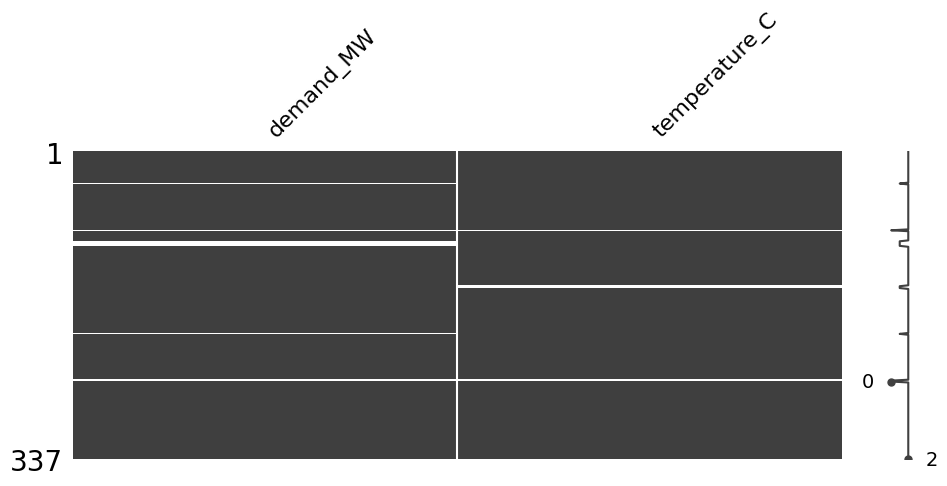

In [41]:
cols = ["demand_MW", "temperature_C"]

if MISSINGNO_AVAILABLE:
    msno.matrix(df[cols], figsize=(11, 4))
    plt.show()
else:
    plt.figure(figsize=(11, 2.5))
    plt.imshow(df[cols].isna().T, aspect="auto", interpolation="nearest")
    plt.yticks(range(len(cols)), cols)
    plt.xlabel("Time index")
    plt.title("Missing values (bright = missing)")
    plt.show()

### Task 2.2 — Find consecutive gaps

The helper below reports lengths of missing blocks. Change `column` in the widget/dropdown.

In [42]:
# @title
def missing_blocks(series):
    m = series.isna()
    group = (m != m.shift(fill_value=False)).cumsum()
    blocks = []
    for _, part in series.groupby(group):
        if part.isna().all():
            blocks.append({
                "start": part.index.min(),
                "end": part.index.max(),
                "hours": len(part),
            })
    return pd.DataFrame(blocks)

def show_missing_blocks(column="demand_MW"):
    out = missing_blocks(df[column])
    print(f"Missing blocks in {column}: {len(out)}")
    display(out if len(out) else pd.DataFrame({"message": ["No missing blocks"]}))

if WIDGETS_AVAILABLE:
    interact(show_missing_blocks, column=["demand_MW", "temperature_C"]);
else:
    show_missing_blocks("demand_MW")
    show_missing_blocks("temperature_C")

interactive(children=(Dropdown(description='column', options=('demand_MW', 'temperature_C'), value='demand_MW'…

### ✍️ Checkpoint 2

1. Is a one-hour gap equivalent to a six-hour gap for imputation?
2. Which is more dangerous for a forecasting dataset: a missing value you can see, or a missing timestamp you fail to detect?
3. Would you use the same imputation rule for demand and temperature? Why/why not?

In [43]:
checkpoint_2 = {
    "Q1": "",
    "Q2": "",
    "Q3": "",
}
checkpoint_2

{'Q1': '', 'Q2': '', 'Q3': ''}

## 🧪 Imputation Playground

Instead of guessing, we can **hide known values deliberately** and see how well each method reconstructs them.

The benchmark hides six consecutive demand observations whose true values are known internally.

In [44]:
def impute_series(s, method):
    out = s.copy()

    if method == "Forward fill":
        return out.ffill()
    if method == "Backward fill":
        return out.bfill()
    if method == "Mean":
        return out.fillna(out.mean())
    if method == "Median":
        return out.fillna(out.median())
    if method == "Linear interpolation":
        return out.interpolate(method="linear")
    if method == "Time interpolation":
        return out.interpolate(method="time")
    if method == "Hourly median":
        hourly = out.groupby(out.index.hour).median()
        fill = pd.Series(out.index.hour, index=out.index).map(hourly)
        return out.fillna(fill)
    raise ValueError(method)

# A clean two-day window, away from DST and injected sensor errors.
_benchmark = _truth.set_index("timestamp").loc["2024-10-25":"2024-10-26", "demand_MW"].copy()
_gap_start = pd.Timestamp("2024-10-26 03:00")
_gap_end = pd.Timestamp("2024-10-26 08:00")
_gap_mask = (_benchmark.index >= _gap_start) & (_benchmark.index <= _gap_end)

# Wider reference used by the hourly-median method.
_reference = _truth.set_index("timestamp")["demand_MW"].copy()
_reference = _reference[~_reference.index.duplicated(keep="first")]

def evaluate_imputation(method="Time interpolation"):
    observed = _benchmark.copy()
    truth_gap = observed.loc[_gap_mask].copy()
    observed.loc[_gap_mask] = np.nan

    if method == "Hourly median":
        hourly = _reference.groupby(_reference.index.hour).median()
        imputed = observed.copy()
        fill = pd.Series(imputed.index.hour, index=imputed.index).map(hourly)
        imputed = imputed.fillna(fill)
    else:
        imputed = impute_series(observed, method)

    pred = imputed.loc[_gap_mask]
    rmse = float(np.sqrt(np.mean((pred.to_numpy() - truth_gap.to_numpy()) ** 2)))

    plt.figure(figsize=(11, 4))
    plt.plot(_benchmark.index, _benchmark.values, label="true series", alpha=0.45)
    plt.plot(observed.index, observed.values, marker="o", ms=3, label="observed")
    plt.plot(pred.index, pred.values, marker="o", lw=2.5, label=f"imputed: {method}")
    plt.axvspan(_gap_start, _gap_end, alpha=0.12)
    plt.ylabel("Demand (MW)")
    plt.title(f"{method} — hidden-gap RMSE = {rmse:.1f} MW")
    plt.legend()
    plt.show()
    return rmse

_methods = [
    "Forward fill", "Backward fill", "Mean", "Median",
    "Linear interpolation", "Time interpolation", "Hourly median"
]

if WIDGETS_AVAILABLE:
    interact(evaluate_imputation, method=_methods);
else:
    evaluate_imputation("Time interpolation")

interactive(children=(Dropdown(description='method', index=5, options=('Forward fill', 'Backward fill', 'Mean'…

### Task 2.3 — Compare all methods numerically

Run the cell. Then change `BEST_METHOD_GUESS` to your preferred method **before** looking at the sorted table.

In [45]:
BEST_METHOD_GUESS = "Time interpolation"  # change if you want

_scores = {}
for method in _methods:
    observed = _benchmark.copy()
    truth_gap = observed.loc[_gap_mask].copy()
    observed.loc[_gap_mask] = np.nan
    if method == "Hourly median":
        hourly = _reference.groupby(_reference.index.hour).median()
        fill = pd.Series(observed.index.hour, index=observed.index).map(hourly)
        pred_series = observed.fillna(fill)
    else:
        pred_series = impute_series(observed, method)
    pred = pred_series.loc[_gap_mask]
    _scores[method] = np.sqrt(np.mean((pred.to_numpy() - truth_gap.to_numpy()) ** 2))

score_table = (
    pd.Series(_scores, name="RMSE_MW")
    .sort_values()
    .round(2)
    .to_frame()
)
score_table["your_guess"] = score_table.index == BEST_METHOD_GUESS
display(score_table)

,RMSE_MW,your_guess
Hourly median,10.52,False
Linear interpolation,18.85,False
Time interpolation,18.85,True
Median,45.21,False
Forward fill,55.53,False
Mean,59.95,False
Backward fill,62.98,False


### 🤖 LLM checkpoint — imputation

Ask an LLM something like:

> *I have hourly electricity demand data with a six-hour missing block from 03:00–08:00. Which imputation method should I use: forward fill, interpolation, global mean/median, or hour-of-day median? Explain the assumptions behind your choice.*

Then compare the recommendation with your empirical benchmark.

**Important:** the LLM does not know the hidden ground truth. Your experiment does.

In [46]:
llm_imputation_review = {
    "LLM_recommendation": "",
    "best_empirical_method": score_table.index[0],
    "agree_or_disagree": "",
    "reason": "",
}
llm_imputation_review

{'LLM_recommendation': '',
 'best_empirical_method': 'Hourly median',
 'agree_or_disagree': '',
 'reason': ''}

### Task 2.4 — Create an imputed working copy

For this lab we use a **hybrid rule**:

- temperature → time interpolation;
- demand → time interpolation for short gaps, then hour-of-day median for anything still missing.

You may later argue for a different policy.

In [47]:
work = df.copy()

# Temperature is usually smooth enough for local interpolation over short gaps.
work["temperature_C"] = work["temperature_C"].interpolate(method="time", limit=6, limit_direction="both")

# Demand: interpolate only short gaps first.
work["demand_MW"] = work["demand_MW"].interpolate(method="time", limit=2, limit_direction="both")

# Fill any remaining demand gaps with a robust hour-of-day profile.
hourly_median = work.groupby(work.index.hour)["demand_MW"].median()
hourly_fill = pd.Series(work.index.hour, index=work.index).map(hourly_median)
work["demand_MW"] = work["demand_MW"].fillna(hourly_fill)

print(work[["demand_MW", "temperature_C"]].isna().sum())

demand_MW        0
temperature_C    0
dtype: int64


---
# 3️⃣ Outlier Detective 🚨

Now all required values exist, but some measurements are suspicious.

Remember:

> **statistical outlier ≠ measurement error**

,count,mean,std,min,25%,50%,75%,max
demand_MW,337.0,922.512817,105.226249,70.677764,878.863428,916.991486,958.433369,1867.672425
temperature_C,337.0,5.991432,2.323087,1.083872,3.928571,5.980312,7.997687,10.438171


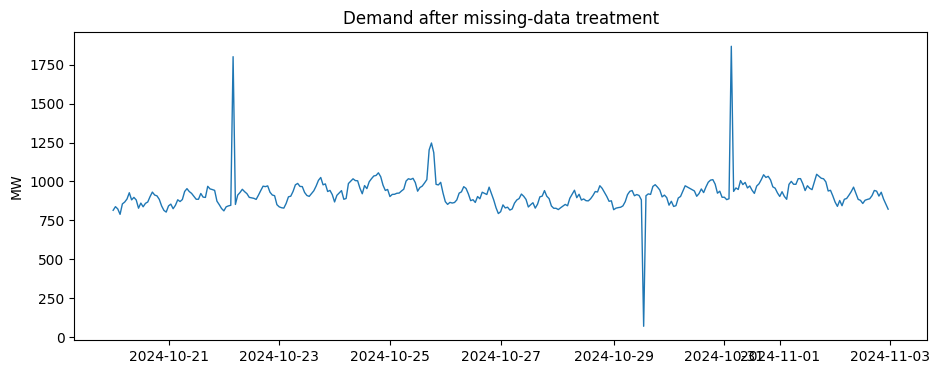

In [48]:
display(work[["demand_MW", "temperature_C"]].describe().T)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(work.index, work["demand_MW"], lw=1)
ax.set_title("Demand after missing-data treatment")
ax.set_ylabel("MW")
plt.show()

### Task 3.1 — IQR detector

The standard rule uses `k = 1.5`. Change it to 1.0, 2.0 and 3.0 and observe how the number of flagged points changes.

In [49]:
def iqr_mask(series, k=1.5):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - k * iqr
    upper = q3 + k * iqr
    return (series < lower) | (series > upper), lower, upper

mask_iqr, lower_iqr, upper_iqr = iqr_mask(work["demand_MW"], k=1.5)
print("IQR flags:", int(mask_iqr.sum()))
print(f"Bounds: {lower_iqr:.1f} .. {upper_iqr:.1f} MW")

IQR flags: 6
Bounds: 759.5 .. 1077.8 MW


### Task 3.2 — Z-score detector

Change the threshold from `3.0` to `2.0` and `4.0`. Why do the results differ from IQR?

In [50]:
def zscore_mask(series, threshold=3.0):
    z = (series - series.mean()) / series.std(ddof=0)
    return z.abs() > threshold

mask_z = zscore_mask(work["demand_MW"], threshold=3.0)
print("Z-score flags:", int(mask_z.sum()))
print("Flagged by both:", int((mask_iqr & mask_z).sum()))

Z-score flags: 4
Flagged by both: 4


## 🎚️ Outlier Threshold Playground

Move the threshold and compare IQR with Z-score visually.

In [51]:
# @title
def outlier_playground(method="IQR", threshold=1.5):
    s = work["demand_MW"]
    if method == "IQR":
        mask, _, _ = iqr_mask(s, k=float(threshold))
    else:
        mask = zscore_mask(s, threshold=float(threshold))

    plt.figure(figsize=(11, 4))
    plt.plot(s.index, s.values, lw=1, label="demand")
    plt.scatter(s.index[mask], s[mask], s=38, label="flagged")
    plt.ylabel("MW")
    plt.title(f"{method}, threshold={threshold:.1f} → {int(mask.sum())} flagged points")
    plt.legend()
    plt.show()

if WIDGETS_AVAILABLE:
    method_widget = widgets.Dropdown(options=["IQR", "Z-score"], value="IQR", description="Method:")
    threshold_widget = widgets.FloatSlider(value=1.5, min=1.0, max=4.0, step=0.25, description="Threshold:", continuous_update=False)
    interact(outlier_playground, method=method_widget, threshold=threshold_widget);
else:
    outlier_playground("IQR", 1.5)

interactive(children=(Dropdown(description='Method:', options=('IQR', 'Z-score'), value='IQR'), FloatSlider(va…

### Task 3.3 — Inspect suspicious points in context

A detector should **generate candidates**, not make the final decision automatically.

Use the table and local windows below. Pay attention to whether an extreme point is isolated or supported by neighbouring values.

In [52]:
candidate_mask, _, _ = iqr_mask(work["demand_MW"], k=1.5)
candidates = work.loc[candidate_mask, ["demand_MW", "temperature_C"]].copy()
candidates["z_score"] = ((work.loc[candidate_mask, "demand_MW"] - work["demand_MW"].mean()) / work["demand_MW"].std(ddof=0)).round(2)
display(candidates.sort_values("demand_MW").head(12))
display(candidates.sort_values("demand_MW", ascending=False).head(12))

,demand_MW,temperature_C,z_score
timestamp,,,
2024-10-29 13:00:00+02:00,70.677764,7.230024,-8.11
2024-10-25 19:00:00+03:00,1185.101303,5.818003,2.50
2024-10-25 17:00:00+03:00,1202.683264,4.475998,2.67
2024-10-25 18:00:00+03:00,1246.965215,5.234853,3.09
2024-10-22 04:00:00+03:00,1800.982257,7.536901,8.36
2024-10-31 03:00:00+02:00,1867.672425,4.023377,9.00


,demand_MW,temperature_C,z_score
timestamp,,,
2024-10-31 03:00:00+02:00,1867.672425,4.023377,9.00
2024-10-22 04:00:00+03:00,1800.982257,7.536901,8.36
2024-10-25 18:00:00+03:00,1246.965215,5.234853,3.09
2024-10-25 17:00:00+03:00,1202.683264,4.475998,2.67
2024-10-25 19:00:00+03:00,1185.101303,5.818003,2.50
2024-10-29 13:00:00+02:00,70.677764,7.230024,-8.11


,demand_MW,temperature_C
timestamp,,
2024-10-22 01:00:00+03:00,837.350425,9.238771
2024-10-22 02:00:00+03:00,843.445062,8.996822
2024-10-22 03:00:00+03:00,847.019641,8.805147
2024-10-22 04:00:00+03:00,1800.982257,7.536901
2024-10-22 05:00:00+03:00,852.604456,7.757307
2024-10-22 06:00:00+03:00,912.675443,7.452008
2024-10-22 07:00:00+03:00,929.232233,7.205740


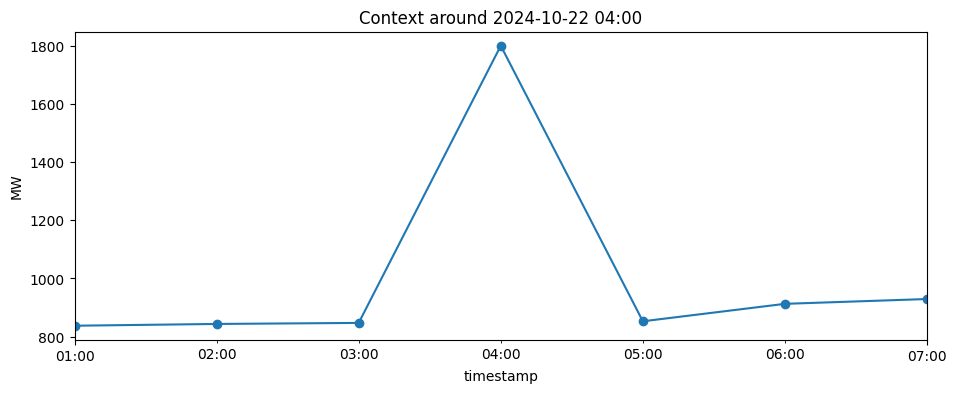

In [53]:
def inspect_window(timestamp, hours=3):
    ts = pd.Timestamp(timestamp, tz="Europe/Tallinn")
    window = work.loc[ts - pd.Timedelta(hours=hours): ts + pd.Timedelta(hours=hours), ["demand_MW", "temperature_C"]]
    display(window)
    ax = window["demand_MW"].plot(marker="o", title=f"Context around {timestamp}")
    ax.set_ylabel("MW")
    plt.show()

# Try changing the timestamp to other suspicious candidates.
inspect_window("2024-10-22 04:00")

### ✍️ Checkpoint 3 — Error or real event?

Classify at least three suspicious points as:

- `likely measurement error`
- `possibly real event`
- `not enough information`

Do **not** justify a decision only with “the value is outside the IQR”.

In [54]:
outlier_review = pd.DataFrame({
    "timestamp": [
        "2024-10-22 04:00",
        "2024-10-25 18:00",
        "2024-10-29 13:00",
        "2024-10-31 03:00",
    ],
    "decision": ["", "", "", ""],
    "reason": ["", "", "", ""],
})
outlier_review

,timestamp,decision,reason
0,2024-10-22 04:00,,
1,2024-10-25 18:00,,
2,2024-10-29 13:00,,
3,2024-10-31 03:00,,


### 🤖 LLM checkpoint — preprocessing audit

Give an LLM this compact report and ask it to propose a cleaning pipeline. Then **audit the answer** rather than accepting it automatically.

In [55]:
report_for_llm = {
    "sampling": "hourly electricity demand + temperature",
    "timezone": "Europe/Tallinn",
    "DST_day_observations": 25,
    "missing_timestamps_found": len(missing_timestamps),
    "longest_demand_gap_hours": int(missing_blocks(df["demand_MW"])["hours"].max()),
    "IQR_flags_k_1_5": int(mask_iqr.sum()),
    "Zscore_flags_3_sigma": int(mask_z.sum()),
}
report_for_llm

{'sampling': 'hourly electricity demand + temperature',
 'timezone': 'Europe/Tallinn',
 'DST_day_observations': 25,
 'missing_timestamps_found': 3,
 'longest_demand_gap_hours': 6,
 'IQR_flags_k_1_5': 6,
 'Zscore_flags_3_sigma': 4}

Suggested prompt:

> *You are reviewing hourly energy data before demand forecasting. The data has a timezone-aware DST transition, several missing timestamps, a six-hour missing-value block, and extreme values flagged by IQR/Z-score. Propose a preprocessing pipeline. For every destructive action (dropping rows, deleting outliers), state the evidence required before doing it.*

Now evaluate the answer.

In [56]:
llm_pipeline_audit = pd.DataFrame({
    "LLM suggestion": [
        "Delete the repeated DST hour",
        "Interpolate every missing block",
        "Delete every IQR outlier",
        "Sort and validate the time index",
    ],
    "Accept?": ["", "", "", ""],
    "Why?": ["", "", "", ""],
})
llm_pipeline_audit

,LLM suggestion,Accept?,Why?
0,Delete the repeated DST hour,,
1,Interpolate every missing block,,
2,Delete every IQR outlier,,
3,Sort and validate the time index,,


---
# 4️⃣ Build the Final Cleaning Pipeline ✅

At this point you should have enough evidence to build a defensible pipeline.

The key idea is:

1. **fix structure first** (time axis),
2. **handle missingness second**,
3. **treat outliers last and conservatively**.

In [57]:
def data_quality_report(frame):
    numeric = frame[["demand_MW", "temperature_C"]]
    iqr_flags, _, _ = iqr_mask(numeric["demand_MW"].dropna(), k=1.5)
    return pd.Series({
        "rows": len(frame),
        "missing_values": int(numeric.isna().sum().sum()),
        "duplicate_timestamps": int(frame.index.duplicated().sum()),
        "IQR_flags_demand": int(iqr_flags.sum()),
    })

print("Current working dataset:")
display(data_quality_report(work).to_frame("value"))

Current working dataset:


,value
rows,337
missing_values,0
duplicate_timestamps,0
IQR_flags_demand,6


### Final task

Create `clean_df` from `work`.

For the practical, use the three timestamps you classified as likely sensor errors. Replace **only those values** with `NaN`, then reconstruct them locally.

This is intentionally different from deleting every statistical outlier.

In [58]:
clean_df = work.copy()

# Add the timestamps that YOU classified as likely measurement errors.
# Example format: "2024-10-22 04:00"
likely_sensor_errors = [
    # "YYYY-MM-DD HH:MM",
]

if likely_sensor_errors:
    error_index = pd.DatetimeIndex(likely_sensor_errors).tz_localize("Europe/Tallinn")
    clean_df.loc[error_index, "demand_MW"] = np.nan
    clean_df["demand_MW"] = clean_df["demand_MW"].interpolate(method="time", limit_direction="both")
else:
    print("⚠️ Add your confirmed sensor-error timestamps to likely_sensor_errors before final submission.")

print("Final quality report:")
display(data_quality_report(clean_df).to_frame("value"))

⚠️ Add your confirmed sensor-error timestamps to likely_sensor_errors before final submission.
Final quality report:


,value
rows,337
missing_values,0
duplicate_timestamps,0
IQR_flags_demand,6


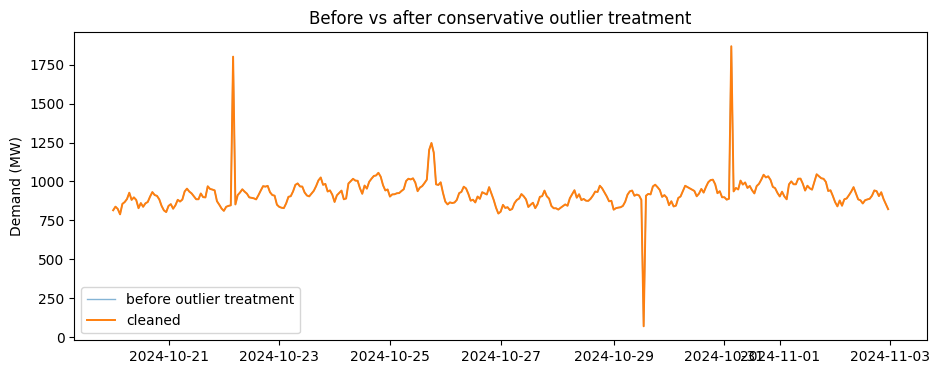

In [59]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(work.index, work["demand_MW"], lw=1, alpha=0.55, label="before outlier treatment")
ax.plot(clean_df.index, clean_df["demand_MW"], lw=1.4, label="cleaned")
ax.set_ylabel("Demand (MW)")
ax.set_title("Before vs after conservative outlier treatment")
ax.legend()
plt.show()

# 🏁 Final mini-challenge

For each case, choose an action and justify it in one sentence.

| Case | Situation |
|---|---|
| A | one missing demand hour |
| B | eight consecutive missing demand hours |
| C | an extreme evening peak supported by neighbouring hours |
| D | one value ≈10× inconsistent with neighbouring hours |
| E | two local records at the repeated DST hour |

Possible actions include: interpolate, use a profile-based estimate, keep, investigate external context, replace as sensor error, localize timezone, or leave unresolved.

In [60]:
final_challenge = pd.DataFrame({
    "case": list("ABCDE"),
    "action": ["", "", "", "", ""],
    "justification": ["", "", "", "", ""],
})
final_challenge

,case,action,justification
0,A,,
1,B,,
2,C,,
3,D,,
4,E,,


## ✅ Takeaways

- A time series can have **missing timestamps even when `.isna()` looks fine**.
- DST can create 23/25-hour local days; repeated local clock labels are not automatically duplicates in absolute time.
- Imputation methods should be compared against the **structure of the signal** and, where possible, empirical masking experiments.
- IQR and Z-score are **candidate detectors**, not truth machines.
- In energy data, an extreme value may be operationally meaningful.
- An LLM can propose hypotheses and code, but the analyst must validate assumptions against data and domain context.